# Sales Analysis Project

Analysis of a public 2019 US electronics sales dataset (12 monthly files combined into one CSV).
The dataset comes from Keith Galli's public *Pandas Data Science Tasks* repository, which I used for guided practice.

**Questions answered**
1. What was the best month for sales, and how much was earned?
2. Which US city had the highest sales?
3. At what time should advertisements be shown to maximise orders?
4. Which products are often sold together?
5. Which products sold the most, and how does price relate to quantity sold?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter

pd.set_option("display.float_format", "{:,.2f}".format)

URL = "https://raw.githubusercontent.com/KeithGalli/Pandas-Data-Science-Tasks/master/SalesAnalysis/Output/all_data.csv"
raw = pd.read_csv(URL)
print("Raw rows:", len(raw))
raw.head()

Raw rows: 186850


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address
0,176558,USB-C Charging Cable,2,11.95,04/19/19 08:46,"917 1st St, Dallas, TX 75001"
1,NaN,NaN,NaN,NaN,NaN,NaN
2,176559,Bose SoundSport Headphones,1,99.99,04/07/19 22:30,"682 Chestnut St, Boston, MA 02215"
3,176560,Google Phone,1,600,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001"
4,176560,Wired Headphones,1,11.99,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001"


## 1. Data cleaning

In [2]:
sales = raw.copy()

# a) rows that are completely empty
blank_rows = sales.isna().all(axis=1).sum()
sales = sales.dropna(how="all")

# b) header rows repeated inside the data (Order Date == "Order Date")
header_rows = (sales["Order Date"].str[0:2] == "Or").sum()
sales = sales[sales["Order Date"].str[0:2] != "Or"].copy()

print(f"Blank rows removed: {blank_rows}")
print(f"Repeated header rows removed: {header_rows}")
print(f"Rows left for analysis: {len(sales)}")

Blank rows removed: 545
Repeated header rows removed: 355
Rows left for analysis: 185950


In [3]:
# Correct data types
sales["Quantity Ordered"] = pd.to_numeric(sales["Quantity Ordered"])
sales["Price Each"] = pd.to_numeric(sales["Price Each"])
sales["Order Date"] = pd.to_datetime(sales["Order Date"])

# New columns
sales["Month"] = sales["Order Date"].dt.month
sales["Hour"] = sales["Order Date"].dt.hour
sales["Sales"] = sales["Quantity Ordered"] * sales["Price Each"]

def get_city(address):
    return address.split(",")[1].strip()

def get_state(address):
    return address.split(",")[2].split(" ")[1]

# City + state code, because some city names repeat (e.g. Portland ME / Portland OR)
sales["City"] = sales["Purchase Address"].apply(lambda x: f"{get_city(x)} ({get_state(x)})")
sales.head()

/tmp/ipykernel_361/2619739696.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sales["Order Date"] = pd.to_datetime(sales["Order Date"])


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Month,Hour,Sales,City
0,176558,USB-C Charging Cable,2,11.95,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",4,8,23.90,Dallas (TX)
2,176559,Bose SoundSport Headphones,1,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",4,22,99.99,Boston (MA)
3,176560,Google Phone,1,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",4,14,600.00,Los Angeles (CA)
4,176560,Wired Headphones,1,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",4,14,11.99,Los Angeles (CA)
5,176561,Wired Headphones,1,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",4,9,11.99,Los Angeles (CA)


## 2. Best month for sales

Month
1    1,822,256.73
2    2,202,022.42
3    2,807,100.38
4    3,390,670.24
5    3,152,606.75
6    2,577,802.26
7    2,647,775.76
8    2,244,467.88
9    2,097,560.13
10   3,736,726.88
11   3,199,603.20
12   4,613,443.34
Name: Sales, dtype: float64

Best month: 12  |  Sales: $4,613,443.34  |  Share of total: 13.4%


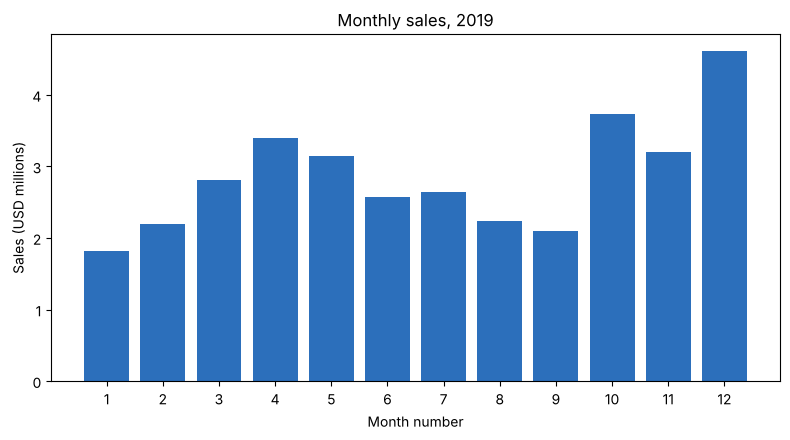

In [4]:
monthly = sales.groupby("Month")["Sales"].sum()
print(monthly)

best_month = monthly.idxmax()
print(f"\nBest month: {best_month}  |  Sales: ${monthly.max():,.2f}  |  Share of total: {monthly.max() / monthly.sum():.1%}")

plt.figure(figsize=(8, 4.5))
plt.bar(monthly.index, monthly.values / 1e6, color="#2c6fbb")
plt.xticks(range(1, 13))
plt.xlabel("Month number")
plt.ylabel("Sales (USD millions)")
plt.title("Monthly sales, 2019")
plt.tight_layout()
plt.show()

## 3. City with the highest sales

City
San Francisco (CA)   8,262,203.91
Los Angeles (CA)     5,452,570.80
New York City (NY)   4,664,317.43
Boston (MA)          3,661,642.01
Atlanta (GA)         2,795,498.58
Dallas (TX)          2,767,975.40
Seattle (WA)         2,747,755.48
Portland (OR)        1,870,732.34
Austin (TX)          1,819,581.75
Portland (ME)          449,758.27
Name: Sales, dtype: float64

Top city: San Francisco (CA)  |  Sales: $8,262,203.91  |  Share of total: 24.0%


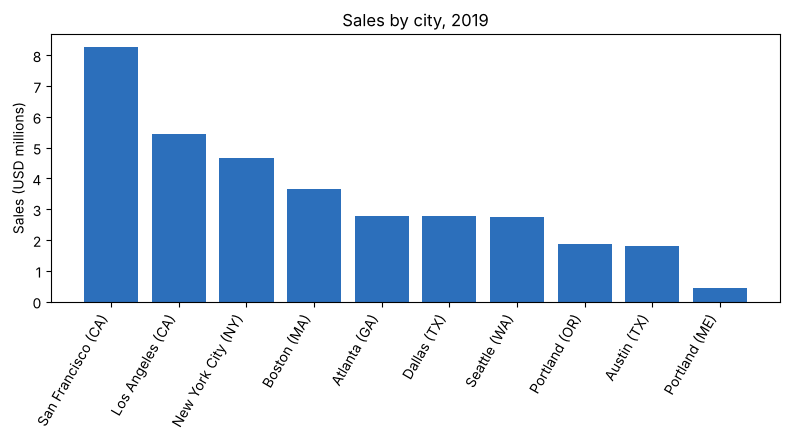

In [5]:
city_sales = sales.groupby("City")["Sales"].sum().sort_values(ascending=False)
print(city_sales)

top_city = city_sales.index[0]
print(f"\nTop city: {top_city}  |  Sales: ${city_sales.iloc[0]:,.2f}  |  Share of total: {city_sales.iloc[0] / city_sales.sum():.1%}")

plt.figure(figsize=(8, 4.5))
plt.bar(city_sales.index, city_sales.values / 1e6, color="#2c6fbb")
plt.xticks(rotation=60, ha="right")
plt.ylabel("Sales (USD millions)")
plt.title("Sales by city, 2019")
plt.tight_layout()
plt.show()

## 4. Best time to show advertisements

Hour
0      3910
1      2350
2      1243
3       831
4       854
5      1321
6      2482
7      4011
8      6256
9      8748
10    10944
11    12411
12    12587
13    12129
14    10984
15    10175
16    10384
17    10899
18    12280
19    12905
20    12228
21    10921
22     8822
23     6275
Name: Order ID, dtype: int64

Top 3 hours by number of orders:
Hour
19    12905
12    12587
11    12411
Name: Order ID, dtype: int64


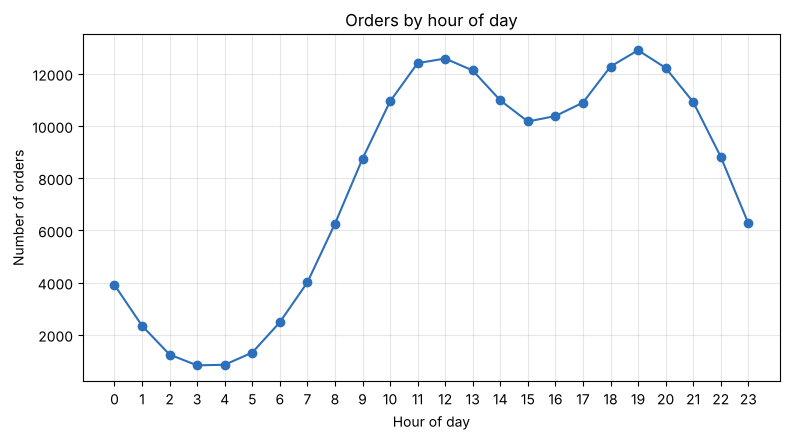

In [6]:
orders_by_hour = sales.groupby("Hour")["Order ID"].count()
print(orders_by_hour)

print("\nTop 3 hours by number of orders:")
print(orders_by_hour.sort_values(ascending=False).head(3))

plt.figure(figsize=(8, 4.5))
plt.plot(orders_by_hour.index, orders_by_hour.values, marker="o", color="#2c6fbb")
plt.xticks(range(0, 24))
plt.xlabel("Hour of day")
plt.ylabel("Number of orders")
plt.title("Orders by hour of day")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Products often sold together

For every order with more than one item, each pair of **different** products in that order is counted once.

In [7]:
multi = sales[sales["Order ID"].duplicated(keep=False)]

pair_counts = Counter()
for _, products in multi.groupby("Order ID")["Product"]:
    unique_products = sorted(set(products))
    pair_counts.update(combinations(unique_products, 2))

top_pairs = pd.DataFrame(
    [(a, b, n) for (a, b), n in pair_counts.most_common(10)],
    columns=["Product 1", "Product 2", "Orders together"],
)
print("Orders with more than one product:", multi["Order ID"].nunique())
top_pairs

Orders with more than one product: 7136


,Product 1,Product 2,Orders together
0,Lightning Charging Cable,iPhone,1011
1,Google Phone,USB-C Charging Cable,997
2,Wired Headphones,iPhone,462
3,Google Phone,Wired Headphones,422
4,Apple Airpods Headphones,iPhone,373
5,USB-C Charging Cable,Vareebadd Phone,368
6,Bose SoundSport Headphones,Google Phone,228
7,USB-C Charging Cable,Wired Headphones,203
8,Vareebadd Phone,Wired Headphones,149
9,Lightning Charging Cable,Wired Headphones,129


## 6. Products sold the most, and price

In [8]:
by_product = sales.groupby("Product").agg(
    quantity=("Quantity Ordered", "sum"),
    avg_price=("Price Each", "mean"),
    revenue=("Sales", "sum"),
).sort_values("quantity", ascending=False)
by_product

,quantity,avg_price,revenue
Product,,,
AAA Batteries (4-pack),31017,2.99,"92,740.83"
AA Batteries (4-pack),27635,3.84,"106,118.40"
USB-C Charging Cable,23975,11.95,"286,501.25"
Lightning Charging Cable,23217,14.95,"347,094.15"
Wired Headphones,20557,11.99,"246,478.43"
Apple Airpods Headphones,15661,150.00,"2,349,150.00"
Bose SoundSport Headphones,13457,99.99,"1,345,565.43"
27in FHD Monitor,7550,149.99,"1,132,424.50"
iPhone,6849,700.00,"4,794,300.00"


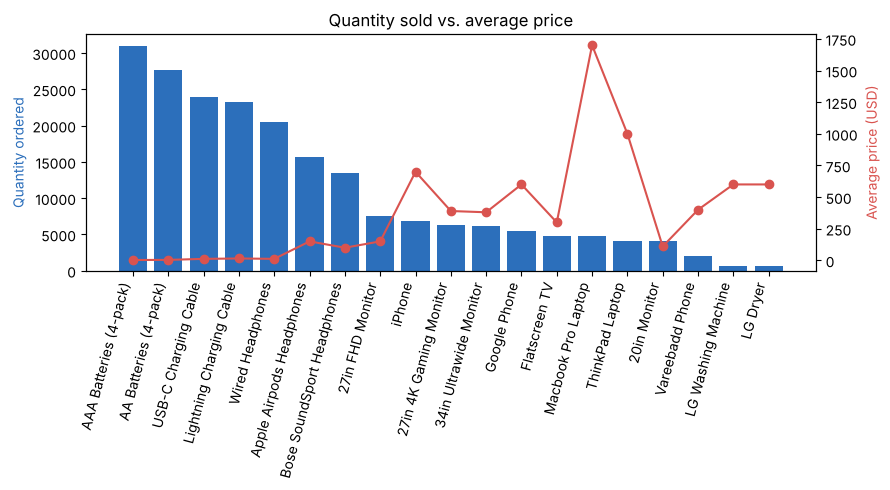

In [9]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()
ax1.bar(by_product.index, by_product["quantity"], color="#2c6fbb")
ax2.plot(by_product.index, by_product["avg_price"], color="#d9534f", marker="o")
ax1.set_ylabel("Quantity ordered", color="#2c6fbb")
ax2.set_ylabel("Average price (USD)", color="#d9534f")
ax1.set_xticks(range(len(by_product)))
ax1.set_xticklabels(by_product.index, rotation=75, ha="right")
plt.title("Quantity sold vs. average price")
plt.tight_layout()
plt.show()

## 7. Summary of findings

In [10]:
total = sales["Sales"].sum()
top_hours = orders_by_hour.sort_values(ascending=False).head(2).index.tolist()
best_product = by_product.index[0]

print(f"Orders analysed:      {len(sales):,}")
print(f"Total sales:          ${total:,.2f}")
print(f"Best month:           {best_month} (${monthly.max():,.2f})")
print(f"Top city:             {top_city} (${city_sales.iloc[0]:,.2f}, {city_sales.iloc[0] / total:.1%} of sales)")
print(f"Busiest order hours:  {top_hours}")
print(f"Most common pair:     {top_pairs.iloc[0, 0]} + {top_pairs.iloc[0, 1]} ({top_pairs.iloc[0, 2]} orders)")
print(f"Most units sold:      {best_product} ({by_product['quantity'].iloc[0]:,} units)")

Orders analysed:      185,950
Total sales:          $34,492,035.97
Best month:           12 ($4,613,443.34)
Top city:             San Francisco (CA) ($8,262,203.91, 24.0% of sales)
Busiest order hours:  [19, 12]
Most common pair:     Lightning Charging Cable + iPhone (1011 orders)
Most units sold:      AAA Batteries (4-pack) (31,017 units)
